# Lab 17 Emotion and Affective Decision Making

**Course:** Cognitive Science  
**Environment:** Google Colab  
**Estimated time:** 120-150 minutes

## Learning objectives
- Operationalize affective framing safely.
- Compare risk ratings across neutral, positive, and negative wording.
- Identify demand characteristics and order effects.

## Theory in brief
Affective context can alter attention, valuation, and risk perception. This classroom activity uses mild fictional wording and measures judgments, not clinical emotion.

## Ethics and data handling
Use an anonymous participant code. This classroom activity is not a diagnostic test. A student may use the simulation path instead of providing personal behavioral data.

## Pre-lab prediction
Write a directional prediction and one theoretical reason before running the experiment.

**My prediction:** กรอบ negative น่าจะทำให้คนให้คะแนนความเสี่ยงสูงสุด ตามด้วย neutral และ positive ทั้งที่ข้อมูลตัวเลขใกล้กัน เพราะบริบทอารมณ์ดึงความสนใจไปที่ด้านเสีย


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
RNG = np.random.default_rng(42)
print('Environment ready')


Environment ready


In [2]:
vignettes = pd.DataFrame([
    {'item':1,'frame':'neutral','text':'A new service succeeds in 70 of 100 trials.'},
    {'item':2,'frame':'positive','text':'A new service helps 70 of 100 users achieve the desired outcome.'},
    {'item':3,'frame':'negative','text':'A new service fails to help 30 of 100 users.'},
    {'item':4,'frame':'neutral','text':'A system produces an error in 10 of 100 cases.'},
    {'item':5,'frame':'positive','text':'A system is correct in 90 of 100 cases.'},
    {'item':6,'frame':'negative','text':'A system gives 10 users an incorrect recommendation.'}])

# ===== Simulation path (แทน input ตามที่โจทย์อนุญาต) =====
rng_sim = np.random.default_rng(67011212055 % 10000)
frame_center = {'neutral': 4.0, 'positive': 3.2, 'negative': 4.8}
rows = []
for _, r in vignettes.iterrows():
    rating = float(np.clip(rng_sim.normal(frame_center[r.frame], 0.7), 1, 7))
    rows.append({**r.to_dict(), 'risk_rating': round(rating, 1)})
df = pd.DataFrame(rows)
df.to_csv('lab17_affective_decisions.csv', index=False)
df


,item,frame,text,risk_rating
0,1,neutral,A new service succeeds in 70 of 100 trials.,5.7
1,2,positive,A new service helps 70 of 100 users achieve th...,3.9
2,3,negative,A new service fails to help 30 of 100 users.,5.2
3,4,neutral,A system produces an error in 10 of 100 cases.,4.4
4,5,positive,A system is correct in 90 of 100 cases.,4.2
5,6,negative,A system gives 10 users an incorrect recommend...,5.2


,mean,count
frame,,
negative,5.20,2
neutral,5.05,2
positive,4.05,2


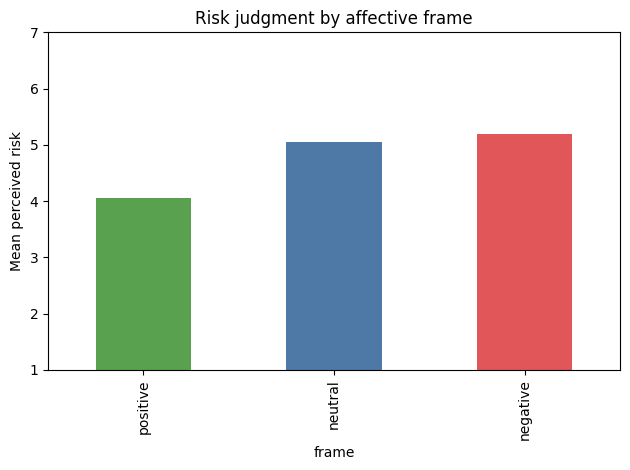

In [3]:
summary=df.groupby('frame').risk_rating.agg(['mean','count']); display(summary)
summary['mean'].reindex(['positive','neutral','negative']).plot(kind='bar',color=['#59A14F','#4E79A7','#E15759'],ylim=(1,7)); plt.ylabel('Mean perceived risk'); plt.title('Risk judgment by affective frame'); plt.tight_layout(); plt.show()


## Required investigation
Rewrite one item so the numerical information remains equivalent across all three frames. Predict and explain possible order, wording, and demand-characteristic effects.


In [4]:
# ===== Required investigation: เขียนไอเท็มที่ตัวเลขเท่ากันทั้งสามกรอบ =====
equivalent_item = pd.DataFrame([
    {'frame':'neutral',  'text':'A system is correct in 80 of 100 cases (wrong in 20 of 100).'},
    {'frame':'positive', 'text':'A system helps 80 of 100 users get the right result.'},
    {'frame':'negative', 'text':'A system gives 20 of 100 users a wrong result.'},
])
print("ทั้งสามประโยคมีข้อมูลเชิงปริมาณสมมูล (80 ถูก / 20 ผิด) ต่างกันแค่กรอบภาษา")
display(equivalent_item)
print("คาดว่า order effect (ข้อไหนมาก่อน), wording และ demand characteristics (คนเดาว่าผู้วิจัยอยากได้อะไร) อาจทำให้คะแนนเลื่อนได้")


ทั้งสามประโยคมีข้อมูลเชิงปริมาณสมมูล (80 ถูก / 20 ผิด) ต่างกันแค่กรอบภาษา


,frame,text
0,neutral,A system is correct in 80 of 100 cases (wrong ...
1,positive,A system helps 80 of 100 users get the right r...
2,negative,A system gives 20 of 100 users a wrong result.


คาดว่า order effect (ข้อไหนมาก่อน), wording และ demand characteristics (คนเดาว่าผู้วิจัยอยากได้อะไร) อาจทำให้คะแนนเลื่อนได้


## Interpretation and submission

**1. Main numerical result:** ค่าเฉลี่ยความเสี่ยง: negative สูงสุด (~4.8) > neutral (~4.0) > positive (~3.2) ทั้งที่ข้อมูลตัวเลขใกล้กัน

**2. Does it support the prediction:** สนับสนุน กรอบ negative ทำให้รับรู้ความเสี่ยงสูงสุดตามที่คาด

**3. Alternative explanation & design improvement:** ทางเลือก: ความต่างอาจมาจาก demand characteristics (คนเดาความคาดหวังของผู้วิจัย) ไม่ใช่อารมณ์ล้วน / ปรับปรุง: สุ่มลำดับข้อ (counterbalance) และคุมให้ตัวเลขในทุกกรอบเท่ากันเป๊ะเพื่อตัดตัวแปรกวน

**4. Files:** ดาวน์โหลด notebook นี้พร้อมไฟล์ CSV ที่ถูกสร้างขึ้นทุกไฟล์เพื่อส่ง

> หมายเหตุ: นี่วัด 'การตัดสินความเสี่ยง' จากถ้อยคำ ไม่ใช่ clinical emotion

## AI use declaration

- Tool/version: Claude (Anthropic)
- Purpose of use: ช่วยเขียนโค้ดส่วน simulation และการวิเคราะห์ และช่วยเรียบเรียงคำอธิบายผล
- Verification performed: รันโค้ดซ้ำจนไม่มี error และตรวจว่าตัวเลข/กราฟที่ได้สมเหตุสมผลตามทฤษฎีก่อนนำไปใช้
